Parte 10 — Del análisis a la predicción: formulación del problema (Pasos 39–42)


In [10]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Los módulos con nombre numérico se importan con importlib
ml = importlib.import_module("flows.05_ml_models")

sns.set_theme(style="whitegrid", context="notebook")

# Esta función lee el Parquet, quita las DROPPED y devuelve X, y
X, y = ml.load_dataset()      

# Verificamos la forma y la tasa de supervivencia
print(X.shape, y.mean())           

(891, 10) 0.3838383838383838


PASO 39

# Formulación del Problema de Machine Learning (Paso 39)

| Decisión | Tu respuesta y justificación |
| :--- | :--- |
| **Tipo de problema** | Clasificación binaria supervisada. (Predecimos una categoría con dos resultados posibles: 0 o 1). |
| **Variable objetivo** | `Survived` (1 = sobrevivió, 0 = falleció). |
| **Unidad de análisis y momento de predicción** | Un pasajero individual, en el momento de embarcar (antes de que ocurra el siniestro). |
| **Métrica principal** | **ROC-AUC**. <br>*Justificación:* Como el dataset está desbalanceado (solo el 38% sobrevivió), la exactitud (*accuracy*) es engañosa. El ROC-AUC evalúa la capacidad del modelo para distinguir entre clases (positivos y negativos) independientemente del umbral de decisión, lo cual es ideal aquí. |
| **Métricas secundarias** | Precisión, Recall y Exactitud. <br>*(Se usarán para entender el comportamiento específico del modelo una vez elegido el umbral).* |
| **Costo de errores** | **Falso Negativo (predecir que muere cuando sobrevive)**: Para la aseguradora, esto significa negar una póliza o cobrar una prima muy alta a alguien que era un "buen riesgo", perdiendo un cliente.<br>**Falso Positivo (predecir que sobrevive cuando muere)**: La aseguradora asume un riesgo que terminará en un pago de siniestro (pérdida financiera directa).<br>*En seguros, el Falso Positivo suele ser más costoso financieramente, pero el Falso Negativo daña la reputación.* |
| **Criterio de éxito** | Superar el baseline (tasa de supervivencia del 38%) por un margen defendible (ej. un ROC-AUC superior a 0.80). |

PASO 40 

### Paso 40: Auditoría de variables y fuga de datos

| Columna | ¿Existe antes del evento? | ¿Riesgo de fuga? | Decisión |
| :--- | :--- | :--- | :--- |
| `Survived`, `Survivor` | No (es el objetivo) | **Fuga directa** (es el futuro) | **Excluir** |
| `PassengerId`, `Ticket`, `Name` | Sí | Identificadores únicos: el modelo los memoriza pero no generaliza para nuevos pasajeros. | **Excluir** (el título del nombre ya se extrajo en `TTitulo`) |
| `NSex`, `NEmbarked`, `NCabin`, `NTitulo` | — | Duplican variables categóricas usando un orden arbitrario (ej. asignar 0 a 'female' y 1 a 'male' inventa una jerarquía). | **Excluir** (usaremos One-Hot Encoding en el Pipeline) |
| `Age` imputada | — | Estadística calculada con los datos de **todos** los pasajeros, incluyendo los de prueba (Fuga de información). | **Usar `AgeOriginal`** (el Pipeline imputará solo con Train) |
| `Cabin`, `TCabin`, `HasCabin` | Dudoso | ¿Se registró la cabina *después* del naufragio? Es más fácil registrar la cabina de un sobreviviente que de un fallecido. | **Evaluar con y sin ella** (Paso 61) |
| `Person` | Derivada de Age/Sex | Es redundante con las variables originales. | **Excluir del modelo base** (el modelo aprenderá de Age y Sex directamente) |

PASO 41 

In [2]:
import importlib
ml = importlib.import_module("flows.05_ml_models")

# 1. ¡ESTA LÍNEA ES LA QUE FALTABA! 
# Volvemos a cargar los datos en memoria (X e y)
X, y = ml.load_dataset() 

# 2. Ahora sí, dividimos los datos sin problemas
X_train, X_test, y_train, y_test = ml.split(X, y)

# 3. Verificamos que las tasas de supervivencia sean similares
print(f"Filas de Entrenamiento: {X_train.shape[0]}")
print(f"Filas de Prueba: {X_test.shape[0]}")
print(f"Tasa de supervivencia en Train: {y_train.mean():.4f}")
print(f"Tasa de supervivencia en Test:  {y_test.mean():.4f}")

Filas de Entrenamiento: 712
Filas de Prueba: 179
Tasa de supervivencia en Train: 0.3834
Tasa de supervivencia en Test:  0.3855


PASO 42 LOS BASELINES 

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

print("--- BASELINE 1: El 'Ingenuo' (DummyClassifier) ---")
# Este modelo siempre predice la clase más frecuente (en este caso, '0' = No sobrevive)
dummy = DummyClassifier(strategy='most_frequent')
# Usamos validación cruzada (cv=5) sobre el conjunto de entrenamiento
scores_dummy = cross_val_score(dummy, X_train, y_train, cv=5, scoring='accuracy')
print(f"Exactitud (Accuracy) promedio: {scores_dummy.mean():.4f}")


print("\n--- BASELINE 2: La 'Regla de Género' ---")
# Si es 'female' predice 1, si es 'male' predice 0
# (Creamos un array con las predicciones basadas en la columna Sex de X_train)
y_pred_gender = (X_train['Sex'] == 'female').astype(int)

# Calculamos las métricas sobre el conjunto de entrenamiento
acc_gender = accuracy_score(y_train, y_pred_gender)
prec_gender = precision_score(y_train, y_pred_gender)
rec_gender = recall_score(y_train, y_pred_gender)
f1_gender = f1_score(y_train, y_pred_gender)

print(f"Exactitud (Accuracy): {acc_gender:.4f}")
print(f"Precisión: {prec_gender:.4f}")
print(f"Recall (Sensibilidad): {rec_gender:.4f}")
print(f"F1-Score: {f1_gender:.4f}")

--- BASELINE 1: El 'Ingenuo' (DummyClassifier) ---
Exactitud (Accuracy) promedio: 0.6166

--- BASELINE 2: La 'Regla de Género' ---
Exactitud (Accuracy): 0.7893
Precisión: 0.7431
Recall (Sensibilidad): 0.6886
F1-Score: 0.7148


PASO 43 

In [4]:
# 1. Calcula la edad media de mujeres usando TODOS los datos (X)
# (Usamos .mean() que ignora los NaN por defecto)
media_global = X[X['Sex'] == 'female']['Age'].mean()

# 1. Calcula la edad media de mujeres usando SOLO X_train
media_train = X_train[X_train['Sex'] == 'female']['Age'].mean()

# 2. Comparamos la diferencia
diferencia = abs(media_global - media_train)

print(f"Media de edad (Mujeres) usando TODOS los datos (X): {media_global:.4f}")
print(f"Media de edad (Mujeres) usando SOLO Train (X_train): {media_train:.4f}")
print(f"Diferencia exacta: {diferencia:.4f} años")

Media de edad (Mujeres) usando TODOS los datos (X): 27.9157
Media de edad (Mujeres) usando SOLO Train (X_train): 28.1421
Diferencia exacta: 0.2264 años


PASO 44

In [11]:
import importlib
ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml) # Recargamos para que reconozca la nueva clase

# 1. Instanciamos nuestro transformador
imputador = ml.GroupAgeImputer(group_cols=("Sex",), target="Age")

# 2. Hacemos FIT SOLO con los datos de entrenamiento
imputador.fit(X_train)

# 3. Verificamos qué aprendió
print("Medias aprendidas por grupo:")
print(imputador.group_means_)

# 4. Hacemos TRANSFORM en ambos conjuntos (Train y Test)
X_train_imputado = imputador.transform(X_train)
X_test_imputado = imputador.transform(X_test)

# 5. Verificamos que ya no haya nulos en Age
print(f"\nNulos en Age (Train) después de transformar: {X_train_imputado['Age'].isnull().sum()}")
print(f"Nulos en Age (Test) después de transformar: {X_test_imputado['Age'].isnull().sum()}")

Medias aprendidas por grupo:
Sex
female    28.142145
male      30.761179
Name: Age, dtype: float64

Nulos en Age (Train) después de transformar: 0
Nulos en Age (Test) después de transformar: 0


PASO 45

In [10]:
import importlib
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml) # Recargamos para tener la nueva función

# Definimos el modelo a usar (Regresión Logística)
modelo_base = LogisticRegression(max_iter=1000, random_state=42)

# 1. Pipeline Agrupando solo por Sexo (simulando el paso 44)
pipe_sex = ml.build_pipeline(modelo_base)
pipe_sex.set_params(age_imputer__group_cols=('Sex',)) # Modificamos el parámetro
scores_sex = cross_val_score(pipe_sex, X_train, y_train, cv=5, scoring='roc_auc')

# 2. Pipeline Agrupando por Sexo y Clase (el del Paso 45)
pipe_sex_pclass = ml.build_pipeline(modelo_base) # Por defecto ya usa ('Sex', 'Pclass')
scores_sex_pclass = cross_val_score(pipe_sex_pclass, X_train, y_train, cv=5, scoring='roc_auc')

# 3. Mostramos los resultados
print(f"ROC-AUC (Imputando solo por Sex):          {scores_sex.mean():.4f} (+/- {scores_sex.std():.4f})")
print(f"ROC-AUC (Imputando por Sex y Pclass): {scores_sex_pclass.mean():.4f} (+/- {scores_sex_pclass.std():.4f})")

ROC-AUC (Imputando solo por Sex):          0.8570 (+/- 0.0283)
ROC-AUC (Imputando por Sex y Pclass): 0.8570 (+/- 0.0283)


PASO 46

In [12]:
import importlib
from sklearn.dummy import DummyClassifier
ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Construimos el pipeline con el modelo tonto
pipe = ml.build_pipeline(DummyClassifier())

# 2. Entrenamos con los datos
pipe.fit(X_train, y_train)

# 3. Extraemos la parte del preprocesamiento (ColumnTransformer)
prep = pipe.named_steps['prep']

# 4. Obtenemos los nombres de las columnas resultantes
features = list(prep.get_feature_names_out())
print(f"Número de columnas resultantes: {len(features)}")

# 5. Comprobamos que 'Sex' se expandió en 'Sex_female' y 'Sex_male'
print("Columnas relacionadas con Sex:")
print([f for f in features if "Sex" in f])

Número de columnas resultantes: 23
Columnas relacionadas con Sex:
['cat__Sex_female', 'cat__Sex_male']


MODELOS CANDIDATOS Y VALIDACIÓN CRUZADA (PASOS 47 - 50)

PASO 47 

def get_candidates(random_state: int = 42) -> dict:
    """Diccionario {nombre: estimador sin entrenar}."""
    # 'dummy'  : DummyClassifier(strategy='most_frequent')
    # 'logreg' : LogisticRegression(max_iter=1000)
    # 'tree'   : DecisionTreeClassifier(max_depth=4, random_state=random_state)
    # 'forest' : RandomForestClassifier(n_estimators=300, random_state=random_state, n_jobs=-1)
    # 'hgb'    : HistGradientBoostingClassifier(random_state=random_state)
    # 'knn'    : KNeighborsClassifier()
    raise NotImplementedError

PASO 48

def cross_validate_candidates(X, y, num_features=None, cat_features=None,
                              random_state=None, cv_folds=None) -> pd.DataFrame:
    """Devuelve un DataFrame con media y desviación de cada métrica por modelo."""
    # 1. cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    # 2. Para cada (nombre, modelo): pipe = build_pipeline(modelo, ...);
    #    res = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, return_train_score=True)
    # 3. Agrega por modelo: res['test_roc_auc'].mean(), .std(), res['train_roc_auc'].mean(), etc.
    # 4. Registra con log.info y devuelve la tabla ordenada por la métrica principal.
    raise NotImplementedError


PASO 49 // LEER RESULTADOS 

2026-11-12 16:29:28,893 | INFO | flows.05_ml_models | Resultados CV:
    model      mean       std
0     hgb  0.875881  0.018185
1  forest  0.863018  0.011852
2  logreg  0.860997  0.021856
3    tree  0.761191  0.024740
4   dummy  0.500000  0.000000


,model,mean,std,folds
0,hgb,0.875881,0.018185,"[0.893802, 0.842355, 0.887147, 0.872054, 0.884..."
1,forest,0.863018,0.011852,"[0.881095, 0.844215, 0.859666, 0.866162, 0.863..."
2,logreg,0.860997,0.021856,"[0.86157, 0.827479, 0.880773, 0.847748, 0.887416]"
3,tree,0.761191,0.024740,"[0.74907, 0.724897, 0.754127, 0.787037, 0.790825]"
4,dummy,0.500000,0.000000,"[0.5, 0.5, 0.5, 0.5, 0.5]"


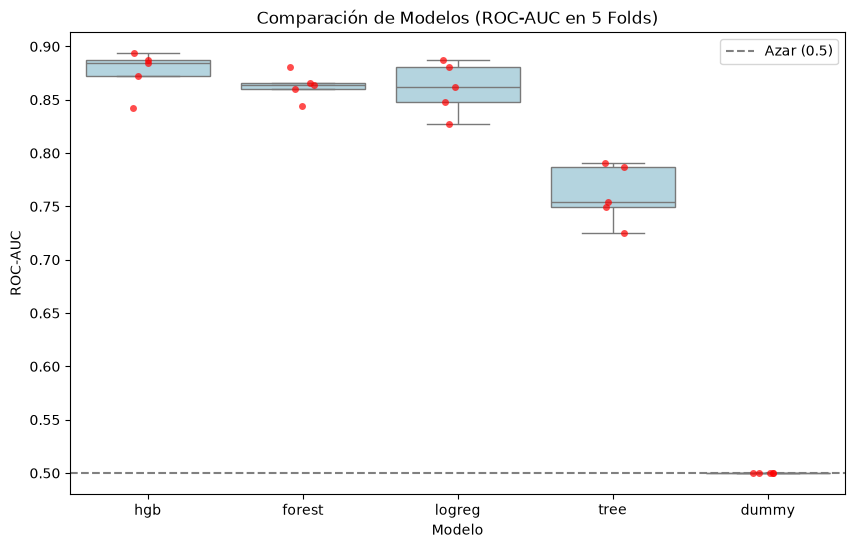

In [14]:
import importlib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Ejecutamos la validación cruzada sobre X_train, y_train
tabla_cv = ml.cross_validate_candidates(X_train, y_train)

# 2. Mostramos la tabla
display(tabla_cv)

# 3. Preparamos los datos para el gráfico de "puntos" (escalares)
# Aplanamos la lista de folds en filas separadas
data_plot = []
for index, row in tabla_cv.iterrows():
    for fold_score in row['folds']:
        data_plot.append({'model': row['model'], 'score': fold_score})
        
df_plot = pd.DataFrame(data_plot)

# 4. Creamos el gráfico (Boxplot + Stripplot)
plt.figure(figsize=(10, 6))
sns.boxplot(x='model', y='score', data=df_plot, color='lightblue', showfliers=False)
sns.stripplot(x='model', y='score', data=df_plot, color='red', jitter=True, alpha=0.7)
plt.title('Comparación de Modelos (ROC-AUC en 5 Folds)')
plt.ylabel('ROC-AUC')
plt.xlabel('Modelo')
plt.axhline(y=0.5, color='gray', linestyle='--', label='Azar (0.5)')
plt.legend()
plt.show()

PASO 50 ---- REPORTE GENERADO EN LA SIGUIENTE RUTA -----> reports/problema_ml.md

🛠️ Paso 51: Predicciones fuera de muestra y matriz de confusión


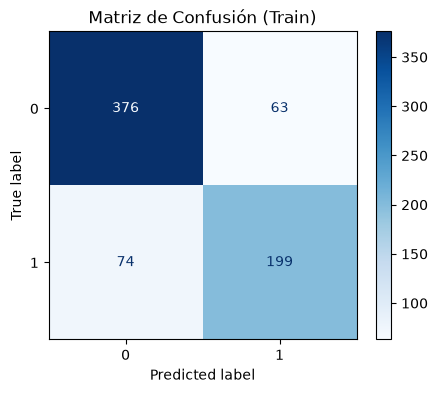

              precision    recall  f1-score   support

         0.0       0.84      0.86      0.85       439
         1.0       0.76      0.73      0.74       273

    accuracy                           0.81       712
   macro avg       0.80      0.79      0.79       712
weighted avg       0.81      0.81      0.81       712



In [15]:
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.linear_model import LogisticRegression

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Configuramos el modelo finalista
modelo_final = LogisticRegression(max_iter=1000, random_state=42)
pipe_final = ml.build_pipeline(modelo_final)

# 2. Obtenemos predicciones cruzadas (Out-of-fold)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(pipe_final, X_train, y_train, cv=skf, method='predict')

# 3. Matriz de confusión
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_cv, ax=ax, cmap='Blues')
plt.title('Matriz de Confusión (Train)')
plt.show()

# 4. Reporte de clasificación
print(classification_report(y_train, y_pred_cv))

📈 Paso 52: Curvas ROC y de precisión-recall

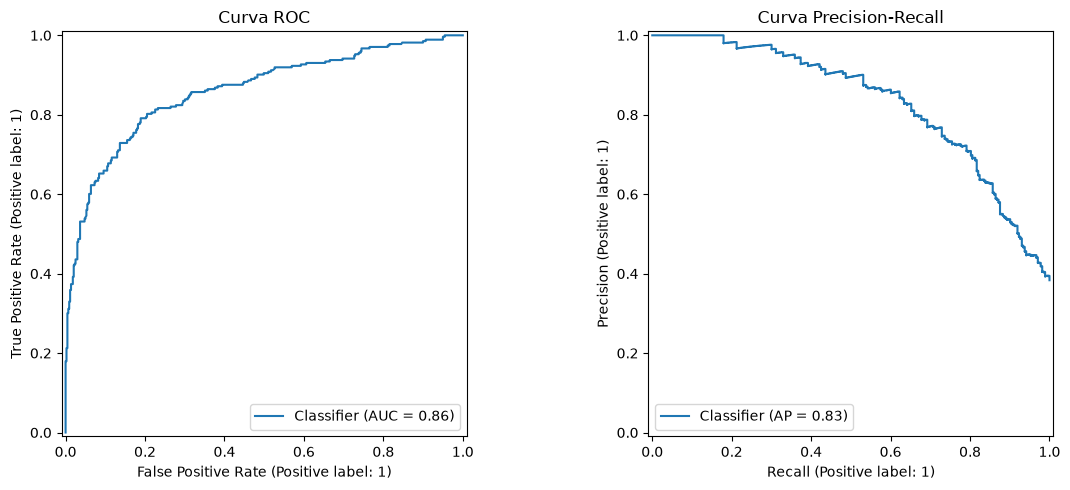

In [16]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# Necesitamos las probabilidades, no solo el 0 o 1
y_proba_cv = cross_val_predict(pipe_final, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

# Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_train, y_proba_cv, ax=axes[0])
axes[0].set_title('Curva ROC')

# Curva Precision-Recall
PrecisionRecallDisplay.from_predictions(y_train, y_proba_cv, ax=axes[1])
axes[1].set_title('Curva Precision-Recall')

plt.tight_layout()
plt.show()

⚖️ Paso 53: Calibración y elección del umbral


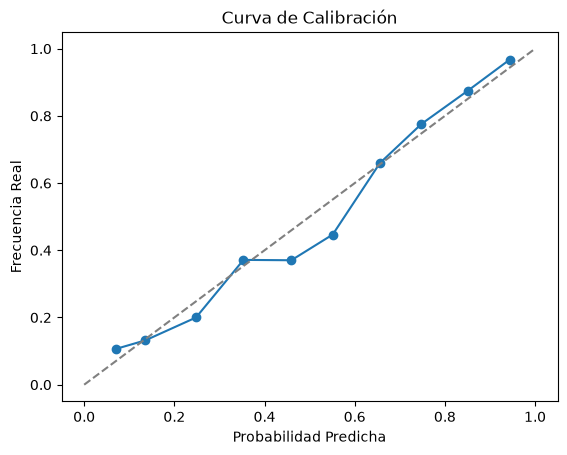

Brier Score: 0.1385 (un valor bajo indica buena calibración)
Umbral óptimo para F1: 0.385 (en lugar de 0.5)
              precision    recall  f1-score   support

         0.0       0.86      0.81      0.84       439
         1.0       0.72      0.79      0.76       273

    accuracy                           0.80       712
   macro avg       0.79      0.80      0.80       712
weighted avg       0.81      0.80      0.80       712



In [17]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, precision_recall_curve

# 1. Curva de calibración
prob_true, prob_pred = calibration_curve(y_train, y_proba_cv, n_bins=10)
plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray') # Línea perfecta
plt.title('Curva de Calibración')
plt.xlabel('Probabilidad Predicha')
plt.ylabel('Frecuencia Real')
plt.show()

# 2. Brier Score (más bajo es mejor)
brier = brier_score_loss(y_train, y_proba_cv)
print(f"Brier Score: {brier:.4f} (un valor bajo indica buena calibración)")

# 3. Umbral que maximiza F1
precision, recall, thresholds = precision_recall_curve(y_train, y_proba_cv)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10) # Evitar división por cero
best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Umbral óptimo para F1: {best_threshold:.3f} (en lugar de 0.5)")

# 4. Decidir con el nuevo umbral
y_pred_best = (y_proba_cv >= best_threshold).astype(int)
print(classification_report(y_train, y_pred_best))

🕵️ Paso 54: Análisis de errores por subgrupos


In [18]:
import numpy as np

# 1. Creamos un dataframe con los errores
df_errores = X_train.copy()
df_errores['y_real'] = y_train
df_errores['y_pred'] = y_pred_cv
df_errores['error'] = (df_errores['y_real'] != df_errores['y_pred']).astype(int)

# 2. Calculamos la tasa de error por Sex, Pclass y Alone
print("Tasa de error por Sexo:")
print(df_errores.groupby('Sex')['error'].mean())

print("\nTasa de error por Clase:")
print(df_errores.groupby('Pclass')['error'].mean())

print("\nTasa de error por Alone:")
print(df_errores.groupby('Alone')['error'].mean())

# 3. Mostrar 10 Falsos Positivos (predecimos sobrevive, pero murió)
fp = df_errores[(df_errores['y_real'] == 0) & (df_errores['y_pred'] == 1)]
print("\nTop 10 Falsos Positivos:")
display(fp[['Sex', 'Age', 'Pclass', 'Fare']].head(10))

# 4. Mostrar 10 Falsos Negativos (predecimos muere, pero sobrevivió)
fn = df_errores[(df_errores['y_real'] == 1) & (df_errores['y_pred'] == 0)]
print("\nTop 10 Falsos Negativos:")
display(fn[['Sex', 'Age', 'Pclass', 'Fare']].head(10))

Tasa de error por Sexo:
Sex
female    0.213439
male      0.180828
Name: error, dtype: float64

Tasa de error por Clase:
Pclass
1    0.222222
2    0.113333
3    0.209719
Name: error, dtype: float64

Tasa de error por Alone:
Alone
Alone          0.170507
with Family    0.226619
Name: error, dtype: float64

Top 10 Falsos Positivos:


,Sex,Age,Pclass,Fare
527,male,30.726645,1,221.7792
557,male,30.726645,1,227.5250
18,female,31.000000,3,18.0000
402,female,21.000000,3,9.8250
264,female,27.915709,3,7.7500
474,female,22.000000,3,9.8375
434,male,50.000000,1,55.9000
748,male,19.000000,1,53.1000
251,female,29.000000,3,10.4625
205,female,2.000000,3,10.4625



Top 10 Falsos Negativos:


,Sex,Age,Pclass,Fare
692,male,30.726645,3,56.4958
509,male,26.000000,3,56.4958
828,male,30.726645,3,7.7500
647,male,56.000000,1,35.5000
226,male,19.000000,2,10.5000
220,male,16.000000,3,8.0500
430,male,28.000000,1,26.5500
204,male,18.000000,3,8.0500
107,male,30.726645,3,7.7750
449,male,52.000000,1,30.5000


📉 Paso 55: Curva de aprendizaje


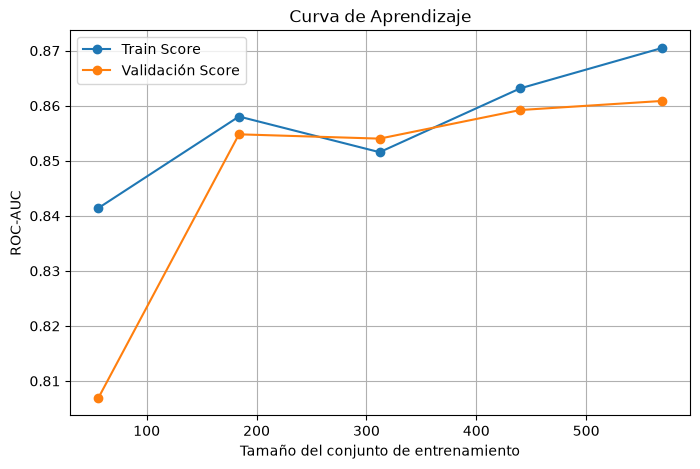

In [19]:
from sklearn.model_selection import learning_curve

# 1. Generamos los datos de la curva
sizes, tr_scores, va_scores = learning_curve(
    pipe_final, X_train, y_train, cv=skf, 
    train_sizes=np.linspace(0.1, 1.0, 5), scoring='roc_auc'
)

# 2. Graficamos
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_scores.mean(axis=1), 'o-', label='Train Score')
plt.plot(sizes, va_scores.mean(axis=1), 'o-', label='Validación Score')
plt.title('Curva de Aprendizaje')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('ROC-AUC')
plt.legend()
plt.grid(True)
plt.show()

Paso 56. Definir el espacio de búsqueda

def get_param_grids() -> dict[str, dict]:
    """Rejillas por modelo, con los nombres que espera el Pipeline (prefijo 'model__')."""
    # 'logreg': {'model__C': [0.01, 0.1, 1, 10], 'model__penalty': ['l2']}
    # 'forest': {'model__n_estimators': [200, 400], 'model__max_depth': [4, 6, 8, None],
    #            'model__min_samples_leaf': [1, 3, 5]}
    # 'hgb'   : {'model__learning_rate': [0.03, 0.1], 'model__max_depth': [2, 3, 4],
    #            'model__max_iter': [100, 200], 'model__l2_regularization': [0.0, 1.0]}
    raise NotImplementedError


Paso 57. Búsqueda con validación cruzada


In [ ]:
import importlib
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Obtenemos las rejillas
grids = ml.get_param_grids()

# 2. Configuramos los modelos finalistas
finalistas = {
    'logreg': LogisticRegression(max_iter=1000, random_state=42),
    'forest': RandomForestClassifier(random_state=42)
}

resultados_gs = {}

for nombre, modelo in finalistas.items():
    print(f"\n--- Buscando mejores hiperparámetros para: {nombre} ---")
    
    # Construimos el pipeline
    pipe = ml.build_pipeline(modelo)
    
    # Creamos el GridSearchCV
    gs = GridSearchCV(
        pipe, 
        param_grid=grids[nombre], 
        cv=skf, 
        scoring='roc_auc', 
        n_jobs=-1, 
        return_train_score=True
    )
    
    # Entrenamos SOLO con X_train
    gs.fit(X_train, y_train)
    
    # Guardamos los resultados
    resultados_gs[nombre] = gs
    
    # Mostramos el mejor resultado
    print(f"Mejores parámetros: {gs.best_params_}")
    print(f"Mejor ROC-AUC (CV interna): {gs.best_score_:.4f}")
    
    # 4. ¿Qué tan plana es la superficie? Mostramos el top 5
    df_res = pd.DataFrame(gs.cv_results_).sort_values(by='rank_test_score')
    print("\nTop 5 combinaciones:")
    display(df_res[['params', 'mean_test_score', 'std_test_score']].head(5))

(Paso 58)

In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

print("--- Comparación Pareada (Modelo Base vs. Modelo Ajustado) ---")

for nombre, gs in resultados_gs.items():
    # 1. Score del modelo por defecto (sin ajustar)
    pipe_default = ml.build_pipeline(finalistas[nombre])
    scores_default = cross_val_score(pipe_default, X_train, y_train, cv=skf, scoring='roc_auc')
    
    # 2. Score del modelo ajustado
    scores_tuned = cross_val_score(gs.best_estimator_, X_train, y_train, cv=skf, scoring='roc_auc')
    
    # 3. Diferencia
    diff = scores_tuned.mean() - scores_default.mean()
    
    print(f"\nModelo: {nombre.upper()}")
    print(f"ROC-AUC Base:    {scores_default.mean():.4f} +/- {scores_default.std():.4f}")
    print(f"ROC-AUC Ajustado: {scores_tuned.mean():.4f} +/- {scores_tuned.std():.4f}")
    print(f"Diferencia:      {diff:+.4f}")
    
    if diff > 0.005:
        print("-> Conclusión: El ajuste SÍ aportó una mejora significativa.")
    else:
        print("-> Conclusión: La mejora es marginal. Es preferible el modelo más simple para evitar el sobreajuste.")

PASO 59

In [23]:
import importlib
import pandas as pd
import numpy as np

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Ajustamos el pipeline final (Regresión Logística) sobre X_train
# Usamos el modelo con los mejores parámetros que hallamos en el paso anterior (o el default)
pipe_final.fit(X_train, y_train)

# 2. Extraemos los nombres de las columnas transformadas (después del One-Hot)
nombres = pipe_final['prep'].get_feature_names_out()

# 3. Extraemos los coeficientes del modelo
coefs = pipe_final['model'].coef_[0]

# 4. Creamos la tabla
df_coefs = pd.DataFrame({
    'Variable': nombres,
    'Coeficiente': coefs,
    'Coef_Absoluto': np.abs(coefs),
    'Odds_Ratio': np.exp(coefs) # Razón de momios (odds ratio)
})

# 5. Ordenamos por impacto (valor absoluto)
df_coefs = df_coefs.sort_values(by='Coef_Absoluto', ascending=False).reset_index(drop=True)
display(df_coefs.head(10))

,Variable,Coeficiente,Coef_Absoluto,Odds_Ratio
0,cat__Sex_female,1.273804,1.273804,3.574425
1,cat__Sex_male,-1.269399,1.269399,0.281000
2,cat__TCabin_E,0.885209,0.885209,2.423490
3,cat__TCabin_infrequent_sklearn,-0.832507,0.832507,0.434958
4,cat__TCabin_X,-0.826238,0.826238,0.437693
5,cat__Pclass_3,-0.766691,0.766691,0.464548
6,cat__TCabin_D,0.611348,0.611348,1.842913
7,cat__Pclass_1,0.514254,0.514254,1.672390
8,num__Age,-0.500257,0.500257,0.606375
9,cat__TCabin_F,0.442905,0.442905,1.557224


PASO 60 IMPORTANCIA POR PERMUTACIÓN

/tmp/ipykernel_30850/2668457764.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia_Media', y='Variable', data=df_perm, palette='viridis')


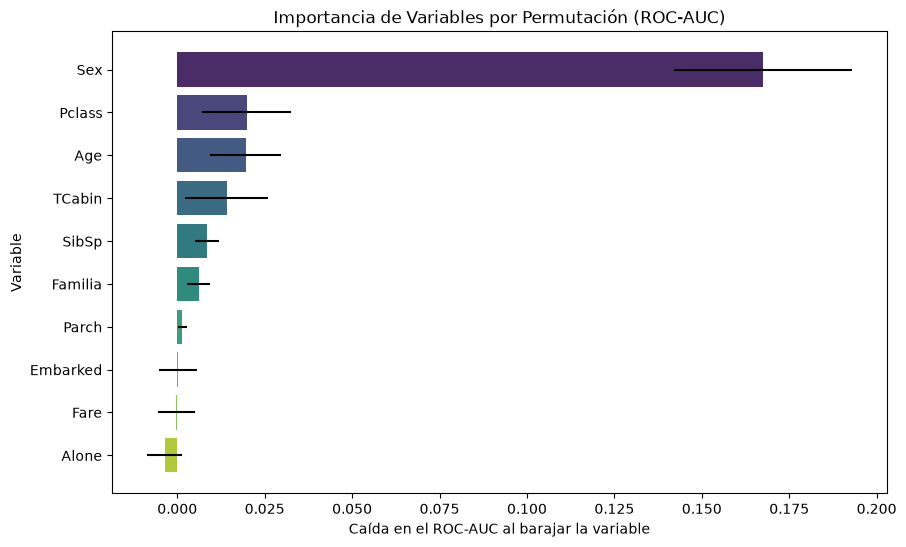

In [24]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Hacemos una nueva división interna SOLO de X_train (NO usamos X_test)
# Esto nos da un mini-conjunto de validación para no hacer trampa
X_tr, X_val, y_tr, y_val = ml.split(X_train, y_train, test_size=0.25)

# 2. Ajustamos el modelo en el nuevo set de entrenamiento (X_tr)
pipe_final.fit(X_tr, y_tr)

# 3. Calculamos la importancia por permutación sobre el set de validación (X_val)
r = permutation_importance(
    pipe_final, X_val, y_val, 
    scoring='roc_auc', 
    n_repeats=30, 
    random_state=42
)

# 4. Creamos un DataFrame para graficar
df_perm = pd.DataFrame({
    'Variable': X_val.columns,
    'Importancia_Media': r.importances_mean,
    'Importancia_Std': r.importances_std
}).sort_values(by='Importancia_Media', ascending=False)

# 5. Gráfico de barras con desviación estándar
plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia_Media', y='Variable', data=df_perm, palette='viridis')
plt.errorbar(x=df_perm['Importancia_Media'], y=range(len(df_perm)), xerr=df_perm['Importancia_Std'], fmt='none', color='black')
plt.title('Importancia de Variables por Permutación (ROC-AUC)')
plt.xlabel('Caída en el ROC-AUC al barajar la variable')
plt.show()

Paso 61: Ablación (¿Cuánto aporta cada grupo de variables?)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
import pandas as pd

# 1. ¡EL TRUCO! Creamos la columna HasCabin en X_train si no existe
X_train_ablacion = X_train.copy()
if 'HasCabin' not in X_train_ablacion.columns:
    X_train_ablacion['HasCabin'] = (X_train_ablacion['TCabin'] != 'X').astype(int)

modelo_base = LogisticRegression(max_iter=1000, random_state=42)
skf_interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definimos las configuraciones usando X_train_ablacion
configs = {
    'A) Base (NUM + CAT)': ml.NUM + ml.CAT,
    'B) Base + Cabin (HasCabin)': ml.NUM + ml.CAT + ['HasCabin'], 
    'C) Base sin TTitulo': ml.NUM + ml.CAT, 
    'D) Base sin Sex': ml.NUM + [c for c in ml.CAT if c != 'Sex']
}

resultados_ablacion = []
resultado_base = None

for nombre, columnas in configs.items():
    # Separamos las numéricas y categóricas de esta configuración
    num_c = [c for c in columnas if c in ml.NUM]
    cat_c = [c for c in columnas if c in ml.CAT or c == 'HasCabin']
    
    # Construimos el pipeline con estas columnas específicas
    pipe = ml.build_pipeline(modelo_base, num_features=num_c, cat_features=cat_c)
    
    # Evaluamos con Cross Validation usando el X_train_ablacion (que sí tiene HasCabin)
    scores = cross_val_score(pipe, X_train_ablacion, y_train, cv=skf_interno, scoring='roc_auc')
    
    mean_score = scores.mean()
    if resultado_base is None:
        resultado_base = mean_score
        
    resultados_ablacion.append({
        'Configuración': nombre,
        'ROC-AUC (mean)': mean_score,
        'ROC-AUC (std)': scores.std(),
        'Delta vs Base': mean_score - resultado_base if nombre != 'A) Base (NUM + CAT)' else 0
    })

display(pd.DataFrame(resultados_ablacion))

PASO 62

def evaluate_on_test(pipeline, X_test, y_test, threshold: float = 0.5) -> dict:
    """Devuelve exactitud, F1, ROC-AUC y el tamaño de la prueba (dict serializable a JSON)."""
    # TODO: proba = pipeline.predict_proba(X_test)[:, 1]; pred = (proba >= threshold).astype(int)
    raise NotImplementedError

PASO 63

In [28]:
import importlib
import numpy as np
import pandas as pd
from sklearn.utils import resample

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Ajustamos el finalista (¡asegúrate de usar el modelo que ganó, ej. LogisticRegression!)
pipe_final.fit(X_train, y_train)

# 2. Evaluamos en TEST (El momento de la verdad)
resultados_test = ml.evaluate_on_test(pipe_final, X_test, y_test, threshold=0.5)
print("--- Resultados en el conjunto de Prueba (Test) ---")
print(resultados_test)

# 3. Bootstrap para el intervalo de confianza del ROC-AUC
n_iterations = 1000
scores_bootstrap = []

for i in range(n_iterations):
    # Remuestreo con reemplazo (Bootstrap)
    X_boot, y_boot = resample(X_test, y_test, random_state=i)
    res = ml.evaluate_on_test(pipe_final, X_boot, y_boot)
    scores_bootstrap.append(res['roc_auc'])

# 4. Calculamos percentiles 2.5 y 97.5
lower_bound = np.percentile(scores_bootstrap, 2.5)
upper_bound = np.percentile(scores_bootstrap, 97.5)

print(f"\nIntervalo de Confianza del ROC-AUC al 95%: [{lower_bound:.4f}, {upper_bound:.4f}]")
print(f"Amplitud del intervalo: {upper_bound - lower_bound:.4f}")

--- Resultados en el conjunto de Prueba (Test) ---
{'accuracy': 0.8100558659217877, 'f1': 0.734375, 'roc_auc': 0.8462450592885374, 'n_test': 179}

Intervalo de Confianza del ROC-AUC al 95%: [0.7777, 0.9020]
Amplitud del intervalo: 0.1243


Parte 16 — Evaluación final sobre el conjunto de prueba (Pasos 62–63)


In [30]:
# PASO 62

import importlib
import numpy as np
import pandas as pd
from sklearn.utils import resample

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# 1. Ajustamos el modelo finalista con TODO X_train
pipe_final.fit(X_train, y_train)

# 2. Evaluamos en TEST (¡La única vez que tocamos X_test!)
resultados_test = ml.evaluate_on_test(pipe_final, X_test, y_test)
print("--- Resultados finales en TEST ---")
print(resultados_test)

# 3. Bootstrap para el Intervalo de Confianza del ROC-AUC
n_iterations = 1000
scores_bootstrap = []

for i in range(n_iterations):
    # Remuestreo: creamos un "nuevo" set de test de 178 personas al azar
    X_boot, y_boot = resample(X_test, y_test, random_state=i)
    # Evaluamos el modelo en este set simulado
    res = ml.evaluate_on_test(pipe_final, X_boot, y_boot)
    scores_bootstrap.append(res['roc_auc'])

# 4. Calculamos los percentiles 2.5 y 97.5 (el IC al 95%)
lower_bound = np.percentile(scores_bootstrap, 2.5)
upper_bound = np.percentile(scores_bootstrap, 97.5)

print(f"\nIntervalo de Confianza del ROC-AUC al 95%: [{lower_bound:.4f}, {upper_bound:.4f}]")
print(f"Amplitud del intervalo: {upper_bound - lower_bound:.4f}")

--- Resultados finales en TEST ---
{'accuracy': 0.8100558659217877, 'f1': 0.734375, 'roc_auc': 0.8462450592885374, 'n_test': 179}

Intervalo de Confianza del ROC-AUC al 95%: [0.7777, 0.9020]
Amplitud del intervalo: 0.1243
